# Groupe 6 · Langues, textes et sciences humaines
## Peut-on reconnaître l'auteur d'un passage, et distinguer une voix africaine d'une voix coloniale ?

**Données** : quatre livres en anglais du domaine public (Project Gutenberg) :
- **Olaudah Equiano**, *The Interesting Narrative of the Life of Olaudah Equiano* (1789), récit d'un Africain réduit en esclavage ;
- **Sol Plaatje**, *Native Life in South Africa* (1916), essai d'un intellectuel sud-africain ;
- **Joseph Conrad**, *Heart of Darkness* (1899), roman d'un auteur européen ;
- **Mary Kingsley**, *Travels in West Africa* (1897), récit de voyage d'une exploratrice anglaise.

**Déroulé**
- **Partie A · Explorer les textes** (étapes 1 à 8) : longueur, vocabulaire, indices de style, passages aberrants
- **Partie B · Construire le modèle** (étapes 9 à 11)
- **Partie C · Analyser les résultats** (étapes 12 à 18) : confusions, passages mal attribués, mots-outils, longueur des passages, stabilité
- **Partie D · Utiliser et conclure** (étapes 19 à 21)

# Partie A · Explorer les textes

## Étape 1 · Installer et importer les outils

In [1]:
# Installe les trois bibliothèques utilisées dans ce notebook (déjà présentes dans Colab : l'installation est alors immédiate).
# Si le message « you may need to restart the kernel » apparaît, on peut l'ignorer.
%pip install -q pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re                                # découper un texte en mots
from collections import Counter          # compter des mots
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer   # transformer des textes en nombres
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

## Étape 2 · Charger les quatre livres

In [3]:
import os

# Les fichiers nécessaires : ils doivent être dans le même dossier que ce notebook.
fichiers = ["equiano.txt", "plaatje.txt", "conrad.txt", "kingsley.txt"]

# Dans Google Colab : si un fichier manque, une fenêtre s'ouvre pour l'envoyer depuis votre ordinateur.
if not all(os.path.exists(f) for f in fichiers):
    from google.colab import files
    files.upload()

livres = {
    "Equiano": open("equiano.txt", encoding="utf-8").read(),
    "Plaatje": open("plaatje.txt", encoding="utf-8").read(),
    "Conrad": open("conrad.txt", encoding="utf-8").read(),
    "Kingsley": open("kingsley.txt", encoding="utf-8").read()}

for auteur, texte in livres.items():
    print(auteur, ":", len(texte.split()), "mots")

Equiano : 80840 mots
Plaatje : 115606 mots
Conrad : 37917 mots
Kingsley : 189415 mots


In [4]:
# Un extrait du livre de Plaatje
print(livres["Plaatje"][5000:5600])

cation
remain loyal to the Government, nobody can buy any land within these areas.
Under the respective charters of these areas, not even a member of the clan
can get a separate title as owner in an area -- let alone a native outsider
who had grown up among white people and done all his farming
on white man's land.

If we exclude the arid tracts of Bechuanaland, these Locations
appear to have been granted on such a small scale that each of them
got so overcrowded that much of the population had to go out and settle
on the farms of white farmers through lack of space in the Locations.
Yet a maj


## Étape 3 · Les mots les plus fréquents de chaque auteur

In [5]:
mots_outils = ["the", "of", "and", "to", "a", "in", "that", "is", "was", "he", "for", "it", "with", "as", "his",
              "on", "be", "at", "by", "i", "this", "had", "not", "are", "but", "from", "or", "have", "an", "they",
              "which", "one", "you", "were", "her", "all", "she", "there", "would", "their", "we", "him", "been",
              "has", "when", "who", "will", "more", "no", "if", "out", "so", "said", "what", "up", "its", "about",
              "into", "than", "them", "can", "only", "other", "some", "could", "these", "may", "then", "do", "any",
              "my", "now", "such", "our", "over", "me", "even", "most", "after", "also", "did", "many", "before",
              "must", "through", "very", "should", "because", "each", "those", "how", "too", "while", "might", "us"]

for auteur, texte in livres.items():
    mots = re.findall(r"[a-z']+", texte.lower())                      # tous les mots, en minuscules
    pleins = [m for m in mots if m not in mots_outils and len(m) > 2]  # on retire les mots-outils et les mots très courts
    print(auteur, ":", ", ".join(m for m, n in Counter(pleins).most_common(15)))

Equiano : time, much, board, ship, great, man, captain, people, went, being, master, came, made, got, day
Plaatje : native, natives, south, government, land, general, africa, act, union, white, law, people, under, against, state
Conrad : kurtz, like, man, see, know, time, seemed, made, back, came, don, little, though, river, looked


Kingsley

 : down, great, like, man, get, men, west, coast, way, being, white, time, water, got, river


Les mots fréquents disent surtout **de quoi parle** chaque livre : le navire et le maître chez Equiano, la loi et les « natives » chez Plaatje, Kurtz chez Conrad, le canoë et la côte chez Kingsley.

## Étape 4 · Découper les livres en passages de 200 mots

Le modèle va apprendre à reconnaître l'auteur d'un **passage**, pas d'un livre entier.

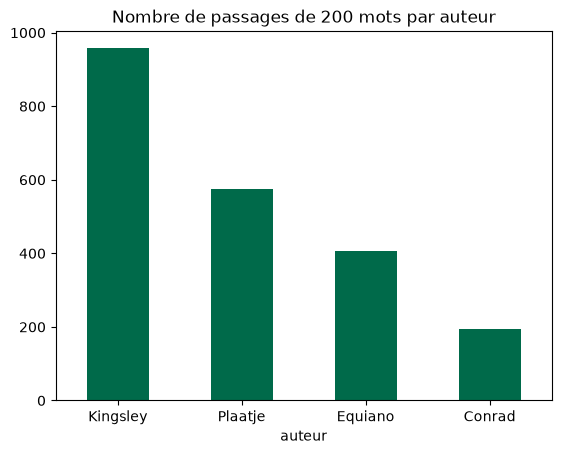

In [6]:
passages = []
for auteur, texte in livres.items():
    mots = re.findall(r"[A-Za-z']+", texte)                  # la liste des mots du livre
    for debut in range(0, len(mots) - 200, 200):              # on avance de 200 mots en 200 mots
        passages.append({"auteur": auteur, "texte": " ".join(mots[debut:debut + 200])})

passages = pd.DataFrame(passages)
passages["auteur"].value_counts().plot(kind="bar", color="#006A4A", rot=0)
plt.title("Nombre de passages de 200 mots par auteur")
plt.show()

Les auteurs ne sont pas équilibrés : Kingsley a cinq fois plus de passages que Conrad. Le modèle verra beaucoup plus d'exemples de Kingsley.

## Étape 5 · Des indices de style mesurables

Pour chaque passage, trois mesures simples :
- la **longueur moyenne des mots** ;
- la **richesse du vocabulaire** : nombre de mots différents / nombre de mots ;
- la part de **la première personne** (*I, me, my*).

In [7]:
listes_de_mots = passages["texte"].str.lower().str.split()          # chaque passage découpé en liste de mots

passages["longueur_mots"] = listes_de_mots.apply(lambda mots: sum(len(m) for m in mots) / len(mots))
passages["richesse"] = listes_de_mots.apply(lambda mots: len(set(mots)) / len(mots))
passages["premiere_personne"] = listes_de_mots.apply(lambda mots: sum(m in ["i", "me", "my"] for m in mots) / len(mots) * 100)

passages.groupby("auteur")[["longueur_mots", "richesse", "premiere_personne"]].mean().round(3)

,longueur_mots,richesse,premiere_personne
auteur,,,
Conrad,4.187,0.638,4.231
Equiano,4.199,0.609,5.496
Kingsley,4.276,0.627,2.123
Plaatje,4.626,0.612,0.422


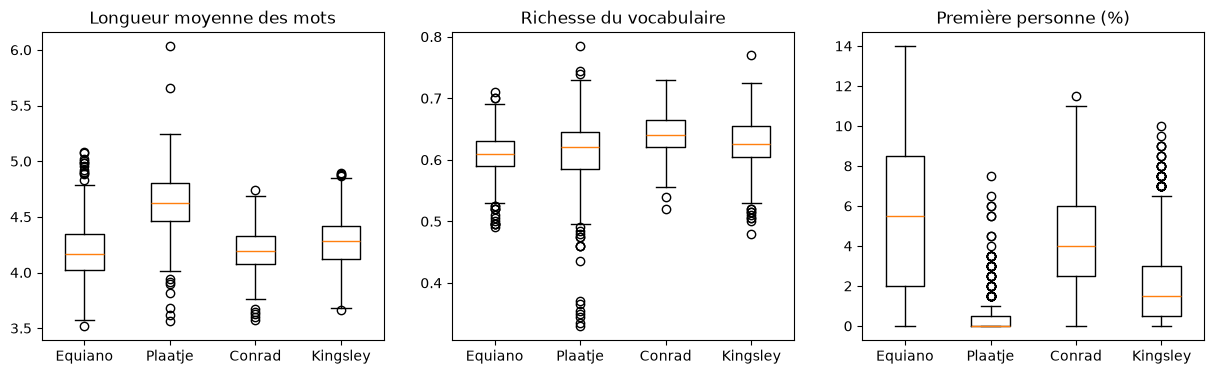

In [8]:
auteurs = ["Equiano", "Plaatje", "Conrad", "Kingsley"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axe, mesure, titre in zip(axes, ["longueur_mots", "richesse", "premiere_personne"],
                              ["Longueur moyenne des mots", "Richesse du vocabulaire", "Première personne (%)"]):
    axe.boxplot([passages[passages["auteur"] == a][mesure] for a in auteurs])
    axe.set_xticks(range(1, 5))
    axe.set_xticklabels(auteurs)
    axe.set_title(titre)
plt.show()

**À regarder** : Equiano écrit à la première personne (c'est une autobiographie). Plaatje emploie des mots plus longs (vocabulaire juridique et politique). Ces seules mesures permettent déjà de distinguer certains auteurs.

## Étape 6 · Les passages aberrants

**La règle des quartiles (ou règle de Tukey)**, la plus utilisée pour repérer des valeurs aberrantes :
- Q1 = la valeur sous laquelle se trouvent 25 % des observations ; Q3 = celle sous laquelle se trouvent 75 % ;
- l'écart interquartile vaut Q3 − Q1 ;
- une valeur est dite **aberrante** si elle est en dessous de Q1 − 1,5 × écart ou au-dessus de Q3 + 1,5 × écart.

Attention : *aberrant* veut dire *inhabituel*, pas forcément *faux*. Chaque valeur repérée se discute avec la connaissance du terrain.

In [9]:
q1 = passages["richesse"].quantile(0.25)
q3 = passages["richesse"].quantile(0.75)
limite_basse = q1 - 1.5 * (q3 - q1)

pauvres = passages[passages["richesse"] < limite_basse]
print("Passages au vocabulaire anormalement pauvre :", len(pauvres))
print(pauvres["auteur"].value_counts())

Passages au vocabulaire anormalement pauvre : 35
auteur
Plaatje     22
Equiano      8
Kingsley     5
Name: count, dtype: int64


In [10]:
# Lisons le passage au vocabulaire le plus pauvre
le_plus_pauvre = passages.loc[passages["richesse"].idxmin()]
print("Auteur :", le_plus_pauvre["auteur"], "| richesse :", round(le_plus_pauvre["richesse"], 2))
print(le_plus_pauvre["texte"][:700])

Auteur : Plaatje | richesse : 0.33
a Camberwell P S A b Mr H A Spong c Masonic Hall Camberwell Surrey d Mr S T Plaatje a Norbury Brotherhood b Mr J L Moody c Wesleyan Church London Rd Norbury d Mr S T Plaatje a Hastings Brotherhood b Mr A G Strickland c Congregational Church Hastings Sussex d Mr S T Plaatje a Evesham Men's Own Brotherhood b Mr G H White c Cowl St Church Evesham Worcestershire d Mr S T Plaatje a South Bank Brotherhood b Mr T Bosher c South Bank on Tees Yorkshire d Mr S T Plaatje a Tees side Brotherhood b Mr T Summers c Wes Church South Bank Yorkshire d Mr S T Plaatje a Shepherd's Bush P S A b Rev W G Davis c Wesleyan Church Shepherd's Bush d Mr S T Plaatje a Stockton United b Mr W Weighell c Baptist Tabernacle


**À discuter** : ces passages sont-ils de la prose normale, ou des listes, des tableaux, des répétitions, des chants ? Un passage aberrant n'est pas une erreur, mais il n'est pas représentatif du style de l'auteur. Ici, on le garde.

## Étape 7 · Les mots-outils, empreinte du style

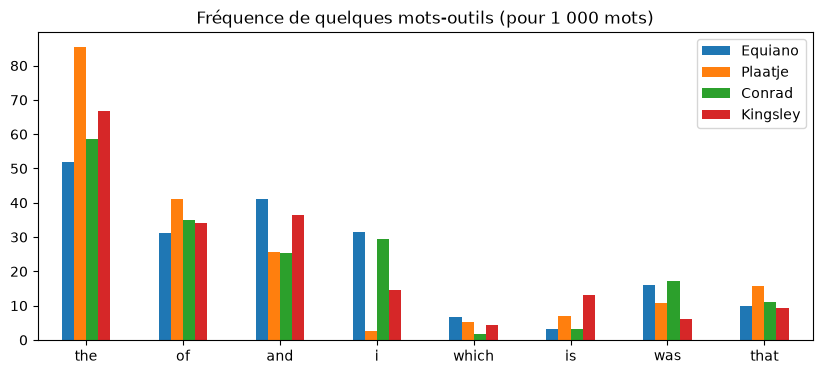

In [11]:
outils_suivis = ["the", "of", "and", "i", "which", "is", "was", "that"]
frequences = {}
for auteur, texte in livres.items():
    mots = re.findall(r"[a-z']+", texte.lower())
    frequences[auteur] = {m: mots.count(m) / len(mots) * 1000 for m in outils_suivis}   # pour 1 000 mots

pd.DataFrame(frequences).plot(kind="bar", figsize=(10, 4), rot=0)
plt.title("Fréquence de quelques mots-outils (pour 1 000 mots)")
plt.show()

Chaque auteur emploie les petits mots à sa manière, sans y penser : c'est le principe de la **stylométrie**.

## Étape 8 · Un passage au hasard

In [12]:
print(passages.sample(1, random_state=3)["texte"].values[0])

I saw in their possession was a few lumps of some stuff like half cooked dough of a dirty lavender colour they kept wrapped in leaves and now and then swallowed a piece of but so small that it seemed done more for the looks of the thing than for any serious purpose of sustenance Why in the name of all the gnawing devils of hunger they didn t go for us they were thirty to five and have a good tuck in for once amazes me now when I think of it They were big powerful men with not much capacity to weigh the consequences with courage with strength even yet though their skins were no longer glossy and their muscles no longer hard And I saw that something restraining one of those human secrets that baffle probability had come into play there I looked at them with a swift quickening of interest not because it occurred to me I might be eaten by them before very long though I own to you that just then I perceived in a new light as it were how unwholesome the pilgrims looked and I hoped yes I posi

# Partie B · Construire le modèle

## Étape 9 · Transformer les mots en nombres (TF-IDF)

Chaque passage devient une liste de nombres : un par mot du vocabulaire. Il est élevé si le mot est fréquent dans ce passage mais rare dans l'ensemble des livres (c'est le principe du **TF-IDF**).

## Étape 10 · Séparer apprentissage et test

In [13]:
textes_apprentissage, textes_test, auteurs_apprentissage, auteurs_test = train_test_split(
    passages["texte"], passages["auteur"], test_size=0.3, stratify=passages["auteur"], random_state=0)

vectoriseur = TfidfVectorizer(max_features=3000)                        # les 3 000 mots les plus fréquents
X_apprentissage = vectoriseur.fit_transform(textes_apprentissage)        # apprend le vocabulaire et transforme
X_test = vectoriseur.transform(textes_test)                              # transforme le test avec le même vocabulaire

print("Passages pour apprendre :", X_apprentissage.shape[0])
print("Passages pour tester :", X_test.shape[0])
print("Nombres par passage :", X_apprentissage.shape[1])

Passages pour apprendre : 1493
Passages pour tester : 640
Nombres par passage : 3000


## Étape 11 · Le modèle : la régression logistique

In [14]:
modele = LogisticRegression(max_iter=3000)
modele.fit(X_apprentissage, auteurs_apprentissage)

predictions = modele.predict(X_test)
print("Passages attribués au bon auteur :", round(accuracy_score(auteurs_test, predictions) * 100, 1), "%")
print("En répondant toujours « Kingsley » :", round((auteurs_test == "Kingsley").mean() * 100, 1), "%")

Passages attribués au bon auteur : 94.1 %
En répondant toujours « Kingsley » : 44.8 %


# Partie C · Analyser les résultats

## Étape 12 · Les confusions

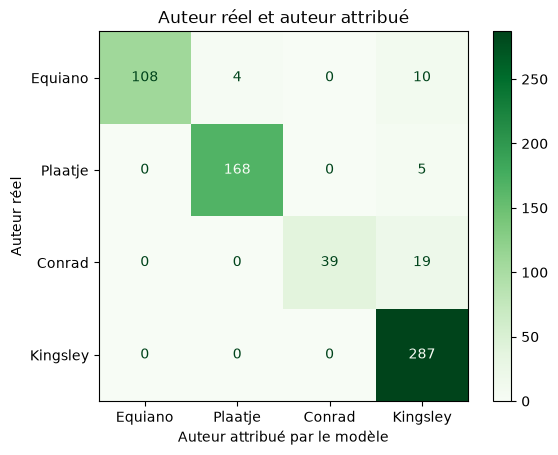

In [15]:
ConfusionMatrixDisplay.from_predictions(auteurs_test, predictions, labels=auteurs, cmap="Greens")
plt.title("Auteur réel et auteur attribué")
plt.xlabel("Auteur attribué par le modèle")
plt.ylabel("Auteur réel")
plt.show()

**À discuter** : quels auteurs sont confondus ? Les confusions se font-elles plutôt entre voix africaines, entre voix européennes, ou d'un groupe à l'autre ?

## Étape 13 · Lire des passages mal attribués

In [16]:
erreurs = pd.DataFrame({"texte": textes_test, "reel": auteurs_test, "attribue": predictions})
erreurs = erreurs[erreurs["reel"] != erreurs["attribue"]]
print("Passages mal attribués :", len(erreurs))

for _, ligne in erreurs.head(3).iterrows():
    print()
    print("Écrit par", ligne["reel"], "· attribué à", ligne["attribue"])
    print(ligne["texte"][:400], "...")

Passages mal attribués : 38

Écrit par Conrad · attribué à Kingsley
and nodded mysteriously Good for you he cried snapped his fingers above his head lifting one foot I tried a jig We capered on the iron deck A frightful clatter came out of that hulk and the virgin forest on the other bank of the creek sent it back in a thundering roll upon the sleeping station It must have made some of the pilgrims sit up in their hovels A dark figure obscured the lighted doorway  ...

Écrit par Conrad · attribué à Kingsley
or hanging to the declivity A continuous noise of the rapids above hovered over this scene of inhabited devastation A lot of people mostly black and naked moved about like ants A jetty projected into the river A blinding sunlight drowned all this at times in a sudden recrudescence of glare There s your Company s station said the Swede pointing to three wooden barrack like structures on the rocky s ...

Écrit par Equiano · attribué à Kingsley
with as little reluctance as the enlighte

**À discuter** : en lisant ces passages, comprenez-vous l'erreur ? Souvent, le passage parle d'un sujet typique d'un autre livre (le fleuve, le voyage, l'esclavage) : le modèle a reconnu le **sujet** plutôt que l'auteur.

## Étape 14 · Les mots qui trahissent chaque auteur

In [17]:
vocabulaire = vectoriseur.get_feature_names_out()

for numero, auteur in enumerate(modele.classes_):
    poids = pd.Series(modele.coef_[numero], index=vocabulaire)
    print(auteur, ":", ", ".join(poids.sort_values(ascending=False).head(12).index))

Conrad : kurtz, had, you, was, he, looked, manager, don, seemed, there, too, know
Equiano : me, my, and, ship, which, master, our, board, we, god, slaves, captain
Kingsley : is, down, coast, canoe, up, and, west, are, fans, has, among, its
Plaatje : natives, south, native, the, general, act, law, coloured, government, farm, mr, land


## Étape 15 · La stylométrie : ne garder que les mots-outils

En ne gardant que les petits mots (*the, of, and, which…*), on force le modèle à reconnaître la **manière d'écrire** plutôt que le sujet.

In [18]:
vectoriseur_style = TfidfVectorizer(vocabulary=mots_outils)
modele_style = LogisticRegression(max_iter=3000)
modele_style.fit(vectoriseur_style.fit_transform(textes_apprentissage), auteurs_apprentissage)

predictions_style = modele_style.predict(vectoriseur_style.transform(textes_test))
print("Avec tout le vocabulaire :", round(accuracy_score(auteurs_test, predictions) * 100, 1), "%")
print("Avec les seuls mots-outils :", round(accuracy_score(auteurs_test, predictions_style) * 100, 1), "%")

Avec tout le vocabulaire : 94.1 %
Avec les seuls mots-outils : 81.1 %


Le score baisse, mais reste élevé : la manière d'écrire suffit en grande partie à reconnaître un auteur.

## Étape 16 · Combien de mots faut-il pour reconnaître un auteur ?

Refaisons tout avec des passages de 25, 50, 100, 200 et 400 mots.

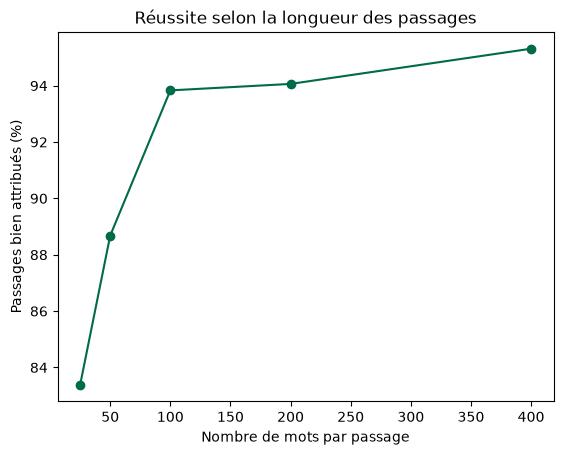

25     83.4
50     88.7
100    93.8
200    94.1
400    95.3
dtype: float64

In [19]:
reussite_selon_longueur = {}
for longueur in [25, 50, 100, 200, 400]:
    morceaux, etiquettes = [], []
    for auteur, texte in livres.items():
        mots = re.findall(r"[A-Za-z']+", texte)
        for debut in range(0, len(mots) - longueur, longueur):
            morceaux.append(" ".join(mots[debut:debut + longueur]))
            etiquettes.append(auteur)
    a, b, ya, yb = train_test_split(morceaux, etiquettes, test_size=0.3, stratify=etiquettes, random_state=0)
    v = TfidfVectorizer(max_features=3000)
    m = LogisticRegression(max_iter=3000).fit(v.fit_transform(a), ya)
    reussite_selon_longueur[longueur] = accuracy_score(yb, m.predict(v.transform(b))) * 100

pd.Series(reussite_selon_longueur).plot(marker="o", color="#006A4A")
plt.title("Réussite selon la longueur des passages")
plt.xlabel("Nombre de mots par passage")
plt.ylabel("Passages bien attribués (%)")
plt.show()
pd.Series(reussite_selon_longueur).round(1)

Plus le passage est long, plus il contient d'indices. **Attribuer un texte très court (une lettre, une inscription) est beaucoup plus risqué.**

## Étape 17 · Voix africaine ou voix coloniale ?

Regroupons Equiano et Plaatje d'un côté, Conrad et Kingsley de l'autre.

In [20]:
voix = {"Equiano": "africaine", "Plaatje": "africaine", "Conrad": "coloniale", "Kingsley": "coloniale"}

modele_voix = LogisticRegression(max_iter=3000)
modele_voix.fit(X_apprentissage, auteurs_apprentissage.map(voix))
print("Voix bien reconnue :", round(accuracy_score(auteurs_test.map(voix), modele_voix.predict(X_test)) * 100, 1), "%")

Voix bien reconnue : 98.4 %


**Attention** : avec deux auteurs de chaque côté, le modèle reconnaît surtout ces quatre livres. Pour parler vraiment de « voix africaine », il faudrait beaucoup plus d'auteurs, d'époques et de genres.

## Étape 18 · La stabilité : la validation croisée

In [21]:
chaine = make_pipeline(TfidfVectorizer(max_features=3000), LogisticRegression(max_iter=3000))
scores = cross_val_score(chaine, passages["texte"], passages["auteur"], cv=5)
print("5 essais :", (scores * 100).round(1), "→ moyenne", round(scores.mean() * 100, 1), "%")

5 essais : [87.6 92.5 94.6 96.7 93.7] → moyenne 93.0 %


# Partie D · Utiliser et conclure

## Étape 19 · Tester un passage que le modèle n'a jamais vu

On prend un passage mis de côté pour le test, comme si on venait de le découvrir dans une archive.

In [22]:
passage = textes_test.iloc[0]
print(passage[:400], "...")
print()
print("Vrai auteur :", auteurs_test.iloc[0])

probabilites = modele.predict_proba(vectoriseur.transform([passage]))[0]
pd.Series(probabilites, index=modele.classes_).round(2).sort_values(ascending=False)

the Rand Sunday Press seem always to have open spaces for rancorous appeals to colour prejudice perhaps because such appeals despite their inherent danger suit the colonial taste Preceding the introduction of the Natives' Land Act the clamour of a section of the colonists and most of the Transvaal Boers for more restrictive measures towards the blacks was accompanied at one of its stages by alarmi ...

Vrai auteur : Plaatje


Plaatje     0.87
Kingsley    0.07
Equiano     0.03
Conrad      0.03
dtype: float64

À vous : remplacez `iloc[0]` par un autre numéro, ou collez votre propre texte entre guillemets à la place de `textes_test.iloc[0]`. En dessous d'une centaine de mots, le modèle se trompe souvent (étape 16).

## Étape 20 · Limites

- Quatre livres seulement, de genres différents : Conrad écrit un roman, les trois autres un récit ou un essai. Le modèle reconnaît aussi le genre et l'époque.
- Les passages d'un même livre se ressemblent : le score est plus facile à obtenir qu'avec des textes vraiment nouveaux.